# Step 10: association rules

Apriori rules with sepsis as the consequent, mined on a sample of train patients and checked on the full validation and test rows.

## Setup and input checks

Imports, constants, helpers and paths come first. Then the known split sizes and the needed columns are checked.

In [1]:
import contextlib, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics import roc_auc_score, average_precision_score
from tqdm import tqdm

warnings.filterwarnings("ignore")

SEED = 42
ROWS_PER_PATIENT = 3
SUPPORT_SWEEP = [0.02, 0.01, 0.005, 0.0025]
MAX_LEN = 4
MIN_LIFT_VAL = 1.5
MIN_MATCHED_VAL = 300
MIN_POS_VAL = 20
SEPTIC, CONTROL = "#d1495b", "#2e86ab"

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 30

SUMMARY, SAVED, COUNTS = [], [], {"pass": 0, "fail": 0}

def log(text=""):
    print(text)
    SUMMARY.append(str(text))

def check(label, ok, detail=""):
    ok = bool(ok)
    COUNTS["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label} ({detail})")
    return ok

def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")

@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")

@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f}s")

def save_fig(name):
    plt.tight_layout()
    path = FIG / name
    plt.savefig(path, dpi=150)
    SAVED.append(path)
    plt.show()
    plt.close()

def need(ok, msg):
    if not ok:
        raise RuntimeError(f"stopping: {msg}")

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "dataset").is_dir():
            return q
    raise FileNotFoundError(f"no folder with a dataset directory above {p}")

ROOT = find_root()
PROC, TAB, FIG = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures"
for d in (PROC, TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)
print(ROOT)

/Users/harnoorkaur/Downloads/Sepsis_ml


In [2]:
NEED = ["patient_id", "split", "hour", "SepsisLabel", "HR", "Resp", "Temp", "MAP", "SBP", "O2Sat", "WBC",
        "Lactate", "Creatinine", "Platelets", "Bilirubin_total", "shock_index", "sirs_count", "n_labs_last6",
        "Lactate_tsl", "Age", "unit_1", "unit_2", "unit_unknown"]

with timed("section 1"):
    log(f"mlxtend version {mlxtend.__version__}")
    cols = pq.read_schema(PROC / "features_flat.parquet").names
    missing = [c for c in NEED if c not in cols]
    check("all needed columns exist in features_flat", not missing, f"missing {missing}")
    need(not missing, "features_flat is missing needed columns")
    df = pd.read_parquet(PROC / "features_flat.parquet", columns=NEED)
    df["split"] = df["split"].astype(str)
    df["patient_id"] = df["patient_id"].astype(str)
    sp = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str})
    log(f"features_flat rows {len(df):,}, patient_splits rows {len(sp):,}")

    known = {"train": (28235, 1085958, 19530), "val": (6050, 234037, 4183), "test": (6051, 232215, 4203)}
    with guarded("split size checks"):
        expect("total rows", len(df), 1552210)
        for s, (npat, nrow, npos) in known.items():
            part = df[df["split"] == s]
            expect(f"{s} patients", part["patient_id"].nunique(), npat)
            expect(f"{s} rows", len(part), nrow)
            expect(f"{s} positive rows", int(part["SepsisLabel"].sum()), npos)
    with guarded("train septic patients"):
        expect("train septic patients", int(sp[sp["split"] == "train"]["ever_septic"].astype(int).sum()), 2052)

mlxtend version 0.25.0
[PASS] all needed columns exist in features_flat (missing [])
features_flat rows 1,552,210, patient_splits rows 40,336
[PASS] total rows (observed 1552210, expected 1552210)
[PASS] train patients (observed 28235, expected 28235)
[PASS] train rows (observed 1085958, expected 1085958)
[PASS] train positive rows (observed 19530, expected 19530)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val rows (observed 234037, expected 234037)
[PASS] val positive rows (observed 4183, expected 4183)
[PASS] test patients (observed 6051, expected 6051)
[PASS] test rows (observed 232215, expected 232215)
[PASS] test positive rows (observed 4203, expected 4203)
[PASS] train septic patients (observed 2052, expected 2052)
section 1: 0.5s


## Items

Each item is a boolean column from the current-hour values, and a missing value never sets an item. The definitions are written to a json file.

In [3]:
DEFS = {
    "HR_gt90": ("HR > 90", lambda d: d["HR"] > 90),
    "Resp_gt20": ("Resp > 20", lambda d: d["Resp"] > 20),
    "Temp_gt38": ("Temp > 38", lambda d: d["Temp"] > 38),
    "Temp_lt36": ("Temp < 36", lambda d: d["Temp"] < 36),
    "MAP_lt65": ("MAP < 65", lambda d: d["MAP"] < 65),
    "SBP_lt100": ("SBP < 100", lambda d: d["SBP"] < 100),
    "O2Sat_lt92": ("O2Sat < 92", lambda d: d["O2Sat"] < 92),
    "ShockIndex_gt09": ("shock_index > 0.9", lambda d: d["shock_index"] > 0.9),
    "SIRS_ge2": ("sirs_count >= 2", lambda d: d["sirs_count"] >= 2),
    "SIRS_ge3": ("sirs_count >= 3", lambda d: d["sirs_count"] >= 3),
    "WBC_abnormal": ("WBC < 4 or WBC > 12", lambda d: (d["WBC"] < 4) | (d["WBC"] > 12)),
    "Lactate_gt2": ("Lactate > 2", lambda d: d["Lactate"] > 2),
    "Creatinine_gt15": ("Creatinine > 1.5", lambda d: d["Creatinine"] > 1.5),
    "Platelets_lt150": ("Platelets < 150", lambda d: d["Platelets"] < 150),
    "Bilirubin_gt2": ("Bilirubin_total > 2", lambda d: d["Bilirubin_total"] > 2),
    "Lactate_measured_6h": ("Lactate not NaN and Lactate_tsl <= 5", lambda d: d["Lactate"].notna() & (d["Lactate_tsl"] <= 5)),
    "Labs_ge3_6h": ("n_labs_last6 >= 3", lambda d: d["n_labs_last6"] >= 3),
    "Age_ge65": ("Age >= 65", lambda d: d["Age"] >= 65),
    "Unit_1": ("unit_1 == 1", lambda d: d["unit_1"] == 1),
    "Unit_2": ("unit_2 == 1", lambda d: d["unit_2"] == 1),
    "Unit_unknown": ("unit_unknown == 1", lambda d: d["unit_unknown"] == 1),
    "Stay_early": ("hour < 12", lambda d: d["hour"] < 12),
    "Stay_late": ("hour >= 24", lambda d: d["hour"] >= 24),
}
ITEMS = list(DEFS)

def build_items(d):
    cols = {k: np.asarray(f(d), dtype=bool) for k, (_, f) in DEFS.items()}
    cols["Sepsis"] = np.asarray(d["SepsisLabel"] == 1, dtype=bool)
    return pd.DataFrame(cols, index=d.index)

with timed("section 2"):
    defs_out = {k: v[0] for k, v in DEFS.items()}
    defs_out["Sepsis"] = "SepsisLabel == 1"
    with open(PROC / "ar_items_definition.json", "w") as f:
        json.dump(defs_out, f, indent=2)
    log(f"{len(ITEMS)} items plus the Sepsis consequent, definitions saved")

23 items plus the Sepsis consequent, definitions saved
section 2: 0.0s


## Sampling transactions from train patients

Every train patient gives at most three rows, and positive rows are favoured for septic patients. The sample is only used for mining.

In [4]:
with timed("section 3"):
    tr = df.loc[df["split"] == "train", ["patient_id", "SepsisLabel"]].copy()
    rng = np.random.default_rng(SEED)
    tr["u"] = rng.random(len(tr))
    tr["rank_in_label"] = tr.groupby(["patient_id", "SepsisLabel"])["u"].rank(method="first")
    # tier 0: up to two positives, tier 1: negatives, tier 2: remaining positives
    tr["tier"] = np.where(tr["SepsisLabel"] == 0, 1, np.where(tr["rank_in_label"] <= 2, 0, 2))
    tr = tr.sort_values(["patient_id", "tier", "u"])
    pick = np.sort(tr.groupby("patient_id").head(ROWS_PER_PATIENT).index.to_numpy())
    sample_rows = df.loc[pick]
    sample = build_items(sample_rows).reset_index(drop=True)
    sample_meta = sample_rows[["patient_id", "split", "SepsisLabel"]].reset_index(drop=True)

    log(f"transactions {len(sample):,} from {sample_meta['patient_id'].nunique():,} train patients")
    log(f"positive share in sample {sample['Sepsis'].mean():.4f} (true train rate {19530 / 1085958:.4f})")
    log("item support in the sample:")
    log(sample.mean().sort_values(ascending=False).to_frame("support").to_string())

    with guarded("sample checks"):
        check("at most 3 rows per patient", sample_meta.groupby("patient_id").size().max() <= ROWS_PER_PATIENT)
        check("all sampled rows are train rows", (sample_meta["split"] == "train").all())
        check("Sepsis column equals SepsisLabel", (sample["Sepsis"].astype(int).to_numpy() == sample_meta["SepsisLabel"].to_numpy()).all())
        check("no NaN in the item table", int(sample.isna().sum().sum()) == 0)
    sample.to_parquet(PROC / "ar_transactions_train.parquet", index=False)

transactions 84,705 from 28,235 train patients
positive share in sample 0.0519 (true train rate 0.0180)
item support in the sample:
                     support
Labs_ge3_6h            0.535
Age_ge65               0.467
Unit_unknown           0.388
Stay_early             0.386
Stay_late              0.316
HR_gt90                0.314
Unit_2                 0.310
Unit_1                 0.302
Resp_gt20              0.275
SIRS_ge2               0.271
WBC_abnormal           0.270
Platelets_lt150        0.210
ShockIndex_gt09        0.145
Creatinine_gt15        0.143
SBP_lt100              0.133
MAP_lt65               0.109
Lactate_measured_6h    0.096
Lactate_gt2            0.080
Temp_lt36              0.075
SIRS_ge3               0.072
Sepsis                 0.052
Temp_gt38              0.044
Bilirubin_gt2          0.033
O2Sat_lt92             0.029
[PASS] at most 3 rows per patient ()
[PASS] all sampled rows are train rows ()
[PASS] Sepsis column equals SepsisLabel ()
[PASS] no NaN in the 

## Single-item lift

Prevalence, P(sepsis | item) and lift are computed on the full validation rows. The test rows are not used here.

validation rows 234,037, base rate 0.0179
               item  rows  positives  prevalence  p_sepsis_given_item  lift
          Temp_gt38 11102        665       0.047                0.060 3.351
           SIRS_ge3 18738        881       0.080                0.047 2.631
Lactate_measured_6h 23909        965       0.102                0.040 2.258
      Bilirubin_gt2 10461        401       0.045                0.038 2.145
           SIRS_ge2 69662       2184       0.298                0.031 1.754
        Lactate_gt2 21297        654       0.091                0.031 1.718
    Creatinine_gt15 37705       1061       0.161                0.028 1.574
       WBC_abnormal 68234       1892       0.292                0.028 1.551
    ShockIndex_gt09 36515       1004       0.156                0.027 1.538
          Resp_gt20 68983       1848       0.295                0.027 1.499
         O2Sat_lt92  7185        191       0.031                0.027 1.487
          Stay_late 97825       2436       0.4

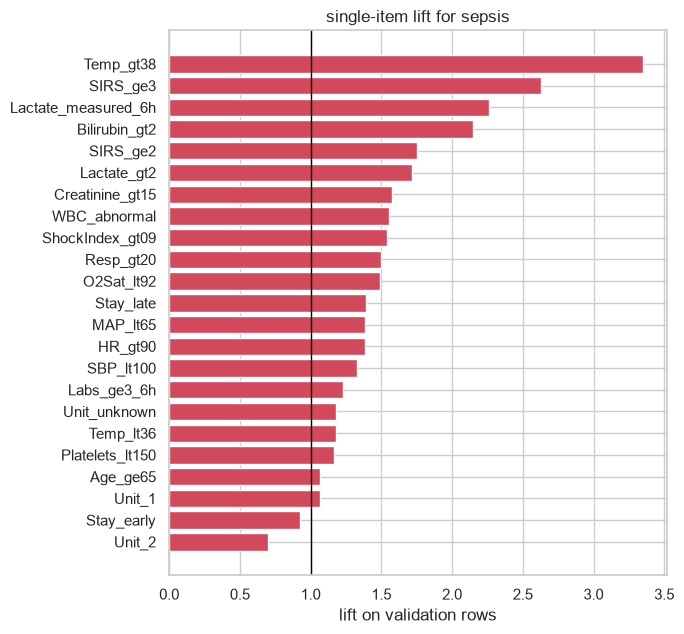

section 4: 0.4s


In [5]:
def item_stats(I):
    y = I["Sepsis"].to_numpy()
    base = y.mean()
    rows = []
    for c in ITEMS:
        m = I[c].to_numpy()
        n = int(m.sum())
        pos = int((m & y).sum())
        p = pos / n if n else np.nan
        rows.append({"item": c, "rows": n, "positives": pos, "prevalence": n / len(I), "p_sepsis_given_item": p, "lift": p / base})
    return pd.DataFrame(rows)

with timed("section 4"):
    val = df[df["split"] == "val"]
    VI = build_items(val)
    BASE_VAL = VI["Sepsis"].mean()
    log(f"validation rows {len(VI):,}, base rate {BASE_VAL:.4f}")
    iv = item_stats(VI)
    iv.to_csv(TAB / "ar_item_lift_val.csv", index=False)
    log(iv.sort_values("lift", ascending=False).head(12).to_string(index=False))
    lk = iv.set_index("item")["lift"]
    for it in ["HR_gt90", "Resp_gt20", "Temp_gt38", "ShockIndex_gt09", "SIRS_ge2", "Lactate_gt2"]:
        log(f"{it}: validation lift {lk[it]:.2f}, {'above 1' if lk[it] > 1 else 'not above 1'}")

    s = iv.sort_values("lift")
    fig, ax = plt.subplots(figsize=(7, 6.5))
    ax.barh(s["item"], s["lift"], color=SEPTIC)
    ax.axvline(1, color="black", lw=1)
    ax.set_xlabel("lift on validation rows")
    ax.set_title("single-item lift for sepsis")
    save_fig("fig10_item_lift.png")

## Apriori

Apriori runs on the boolean sample for each minimum support in the sweep. The smallest support that is fast enough and gives few enough itemsets is used for the rules.

In [6]:
def get_rules(fi, n):
    try:
        return association_rules(fi, metric="lift", min_threshold=0)
    except TypeError as e:
        if "num_itemsets" not in str(e):
            raise
        return association_rules(fi, num_itemsets=n, metric="lift", min_threshold=0)

with timed("section 5"):
    sweep, FI = [], {}
    for s in tqdm(SUPPORT_SWEEP):
        t0 = time.time()
        fi = apriori(sample, min_support=s, use_colnames=True, max_len=MAX_LEN)
        sec = time.time() - t0
        FI[s] = fi
        n_sep = int(fi["itemsets"].apply(lambda x: "Sepsis" in x).sum())
        sweep.append({"min_support": s, "itemsets": len(fi), "itemsets_with_sepsis": n_sep, "seconds": sec})
        log(f"min_support {s}: {len(fi):,} itemsets, {n_sep:,} with Sepsis, {sec:.1f}s")
    sweep = pd.DataFrame(sweep)
    sweep.to_csv(TAB / "ar_support_sweep.csv", index=False)

    ok = sweep[(sweep["seconds"] < 120) & (sweep["itemsets"] <= 50000)]
    need(len(ok) > 0, "no min_support in the sweep meets the time and size limits")
    CHOSEN = float(ok["min_support"].min())
    log(f"chosen min_support {CHOSEN}")

    allr = get_rules(FI[CHOSEN], len(sample))
    only = allr[allr["consequents"].apply(lambda c: c == frozenset({"Sepsis"}))]
    only = only[only["antecedents"].apply(len).between(1, 3)]
    kept = only[only["lift"] > 1.2].copy()
    kept["antecedent"] = kept["antecedents"].apply(lambda a: " AND ".join(sorted(a)))
    kept["antecedent_len"] = kept["antecedents"].apply(len)
    log(f"rules with Sepsis as consequent, 1 to 3 antecedent items, sample lift above 1.2: {len(kept):,}")
    need(len(kept) > 0, "no rules left after the sample filters")
    top = kept.sort_values(["lift", "confidence"], ascending=False).head(200).reset_index(drop=True)
    top[["antecedent", "antecedent_len", "support", "confidence", "lift"]].to_csv(TAB / "ar_rules_train.csv", index=False)
    log(f"saved the best {len(top)} rules by sample lift")
    log(top[["antecedent", "support", "confidence", "lift"]].head(10).to_string(index=False))

    with guarded("sample rule checks"):
        check("every kept rule has consequent {Sepsis} only", kept["consequents"].apply(lambda c: c == frozenset({"Sepsis"})).all())
        check("antecedent length between 1 and 3", kept["antecedent_len"].between(1, 3).all())
        base_s = sample["Sepsis"].mean()
        err = (kept["confidence"] / base_s - kept["lift"]).abs().max()
        check("lift equals confidence / base rate in the sample", err < 1e-9, f"max error {err:.2e}")

 25%|██▌       | 1/4 [00:00<00:00,  5.36it/s]

min_support 0.02: 785 itemsets, 9 with Sepsis, 0.2s


 50%|█████     | 2/4 [00:00<00:00,  2.63it/s]

min_support 0.01: 1,856 itemsets, 55 with Sepsis, 0.5s


 75%|███████▌  | 3/4 [00:01<00:00,  1.37it/s]

min_support 0.005: 3,576 itemsets, 216 with Sepsis, 1.1s


100%|██████████| 4/4 [00:04<00:00,  1.04s/it]

min_support 0.0025: 5,881 itemsets, 564 with Sepsis, 2.3s
chosen min_support 0.0025


rules with Sepsis as consequent, 1 to 3 antecedent items, sample lift above 1.2: 532
saved the best 200 rules by sample lift
                                    antecedent  support  confidence  lift
      Stay_late AND Temp_gt38 AND Unit_unknown    0.003       0.410 7.903
         Resp_gt20 AND Stay_late AND Temp_gt38    0.003       0.358 6.896
          SIRS_ge3 AND Stay_late AND Temp_gt38    0.003       0.353 6.807
      Stay_late AND Temp_gt38 AND WBC_abnormal    0.003       0.348 6.708
       Labs_ge3_6h AND Stay_late AND Temp_gt38    0.004       0.340 6.552
          SIRS_ge2 AND Stay_late AND Temp_gt38    0.005       0.326 6.273
           HR_gt90 AND Stay_late AND Temp_gt38    0.003       0.320 6.171
Lactate_measured_6h AND SIRS_ge2 AND Stay_late    0.004       0.319 6.149
 HR_gt90 AND Lactate_measured_6h AND Stay_late    0.003       0.316 6.078
                       Stay_late AND Temp_gt38    0.005       0.313 6.038
[PASS] every kept rule has consequent {Sepsis} only ()
[PASS]

## Honesty check on the full validation rows

Each candidate rule is recomputed on all validation rows, where the true base rate applies. Rules that hold up are pruned for redundancy and saved before the test rows are touched.

100%|██████████| 200/200 [00:00<00:00, 3825.10it/s]

sample confidence median 0.171, validation confidence median 0.052
sample lift median 3.30, validation lift median 2.88
candidates 200, holding up on validation 200
pruned 51 redundant rules, 149 validated rules remain
validated rules written before the test rows are used
top 15 validated rules:
1. if Stay_late and Temp_gt38 and WBC_abnormal then sepsis: validation lift 5.64, confidence 0.101, matched 2,231, positives 225
2. if Labs_ge3_6h and Stay_late and Temp_gt38 then sepsis: validation lift 5.52, confidence 0.099, matched 3,165, positives 312
3. if Stay_late and Temp_gt38 and Unit_unknown then sepsis: validation lift 5.39, confidence 0.096, matched 2,356, positives 227
4. if Labs_ge3_6h and Lactate_measured_6h and SIRS_ge3 then sepsis: validation lift 5.35, confidence 0.096, matched 2,989, positives 286
5. if Lactate_measured_6h and SIRS_ge3 then sepsis: validation lift 5.35, confidence 0.096, matched 3,012, positives 288
6. if Lactate_measured_6h and SIRS_ge2 and Stay_late then s

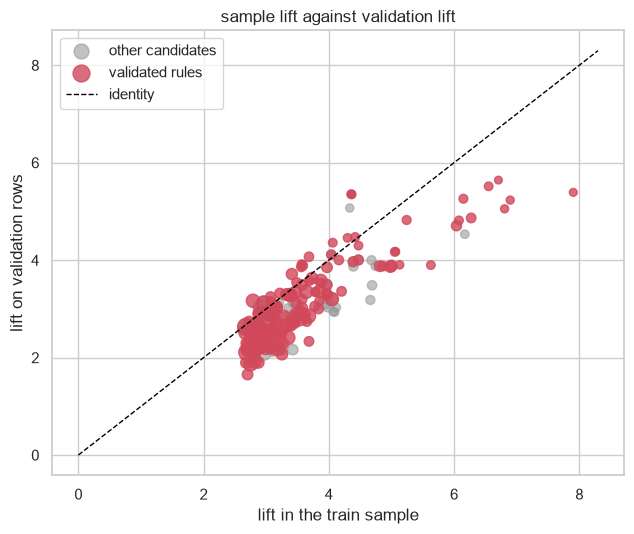

[PASS] validation row count (observed 234037, expected 234037)
[PASS] validation base rate (observed 0.017873242265111926, expected 0.0179)
[PASS] pruned rules have unique antecedents ()
[PASS] manual mask count, rule 130 (observed 5282, expected 5282)
[PASS] manual mask count, rule 17 (observed 4530, expected 4530)
[PASS] manual mask count, rule 154 (observed 15613, expected 15613)
section 6: 0.3s


In [7]:
def rule_items(a):
    return a.split(" AND ")

def mask(I, items):
    m = np.ones(len(I), dtype=bool)
    for it in items:
        m &= I[it].to_numpy()
    return m

def rule_stats(I, ants, suf):
    y = I["Sepsis"].to_numpy()
    base = y.mean()
    out = []
    for a in tqdm(list(ants)):
        m = mask(I, rule_items(a))
        n = int(m.sum())
        pos = int((m & y).sum())
        conf = pos / n if n else np.nan
        out.append({f"matched_rows_{suf}": n, f"positives_{suf}": pos, f"support_{suf}": n / len(I),
                    f"confidence_{suf}": conf, f"lift_{suf}": conf / base})
    return pd.DataFrame(out)

def sentence(i, r, test=False):
    txt = f"{i}. if {' and '.join(rule_items(r['antecedent']))} then sepsis: validation lift {r['lift_val']:.2f}, confidence {r['confidence_val']:.3f}, matched {r['matched_rows_val']:,}, positives {r['positives_val']}"
    if test:
        txt += f"; test lift {r['lift_test']:.2f}, matched {r['matched_rows_test']:,}, positives {r['positives_test']}"
    return txt

with timed("section 6"):
    cand = top[["antecedent", "antecedent_len", "support", "confidence", "lift"]].rename(
        columns={"support": "support_sample", "confidence": "confidence_sample", "lift": "lift_sample"})
    cand = pd.concat([cand, rule_stats(VI, cand["antecedent"], "val")], axis=1)
    log(f"sample confidence median {cand['confidence_sample'].median():.3f}, validation confidence median {cand['confidence_val'].median():.3f}")
    log(f"sample lift median {cand['lift_sample'].median():.2f}, validation lift median {cand['lift_val'].median():.2f}")

    cand["holds"] = (cand["lift_val"] >= MIN_LIFT_VAL) & (cand["matched_rows_val"] >= MIN_MATCHED_VAL) & (cand["positives_val"] >= MIN_POS_VAL)
    hold = cand[cand["holds"]]
    log(f"candidates {len(cand)}, holding up on validation {len(hold)}")
    need(len(hold) > 0, "no candidate rule holds up on the validation rows")

    sets = {i: frozenset(rule_items(a)) for i, a in hold["antecedent"].items()}
    drop = [i for i in hold.index
            if any(sets[j] < sets[i] and hold.at[j, "lift_val"] >= hold.at[i, "lift_val"] for j in hold.index if j != i)]
    validated = hold.drop(index=drop).drop(columns="holds")
    validated = validated.sort_values(["lift_val", "confidence_val"], ascending=False).reset_index(drop=True)
    validated.insert(0, "rank", np.arange(1, len(validated) + 1))
    log(f"pruned {len(drop)} redundant rules, {len(validated)} validated rules remain")

    validated.to_csv(TAB / "ar_rules_validated.csv", index=False)
    with open(PROC / "ar_rules_validated.json", "w") as f:
        json.dump([{"rank": int(r["rank"]), "antecedent": rule_items(r["antecedent"])} for _, r in validated.iterrows()], f, indent=2)
    WRITE_TIME = time.time()
    log("validated rules written before the test rows are used")

    log("top 15 validated rules:")
    for i, r in validated.head(15).iterrows():
        log(sentence(i + 1, r))

    isv = cand["antecedent"].isin(validated["antecedent"]).to_numpy()
    size = (15 + 250 * cand["matched_rows_val"] / cand["matched_rows_val"].max()).fillna(15).to_numpy()
    lim = float(np.nanmax([cand["lift_sample"].max(), cand["lift_val"].max()])) * 1.05
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(cand["lift_sample"][~isv], cand["lift_val"][~isv], s=size[~isv], c="#9a9a9a", alpha=0.6, label="other candidates")
    ax.scatter(cand["lift_sample"][isv], cand["lift_val"][isv], s=size[isv], c=SEPTIC, alpha=0.8, label="validated rules")
    ax.plot([0, lim], [0, lim], color="black", lw=1, ls="--", label="identity")
    ax.set_xlabel("lift in the train sample")
    ax.set_ylabel("lift on validation rows")
    ax.set_title("sample lift against validation lift")
    ax.legend()
    save_fig("fig10_rules_lift_scatter.png")

    with guarded("validation checks"):
        expect("validation row count", len(VI), 234037)
        expect("validation base rate", BASE_VAL, 0.0179, tol=0.0005)
        check("pruned rules have unique antecedents", validated["antecedent"].is_unique)
        r3 = np.random.default_rng(SEED).choice(len(cand), size=3, replace=False)
        for i in r3:
            items = rule_items(cand.at[i, "antecedent"])
            m = np.ones(len(val), dtype=bool)
            for it in items:
                m &= DEFS[it][1](val).to_numpy()
            expect(f"manual mask count, rule {i}", int(m.sum()), int(cand.at[i, "matched_rows_val"]))

## Rules as a score

A row scores the number of the top 10 validated rules it matches. The validation numbers are optimistic because the rules were chosen on validation.

In [8]:
TOP10 = validated.head(10)["antecedent"].tolist()

def score_row(name, I):
    s = sum(mask(I, rule_items(a)).astype(int) for a in TOP10)
    y = I["Sepsis"].to_numpy()
    return {"split": name, "auroc": roc_auc_score(y, s), "auprc": average_precision_score(y, s),
            "base_rate": y.mean(), "rows_matching_any_rule_share": float((s > 0).mean())}

with timed("section 7"):
    scoring = [score_row("val", VI)]
    pd.DataFrame(scoring).to_csv(TAB / "ar_rule_scoring.csv", index=False)
    log(f"rule score on validation (optimistic): AUROC {scoring[0]['auroc']:.3f}, AUPRC {scoring[0]['auprc']:.3f}, base rate {scoring[0]['base_rate']:.4f}")

rule score on validation (optimistic): AUROC 0.582, AUPRC 0.036, base rate 0.0179
section 7: 0.1s


## Test, once

The saved validated rules are applied to the test rows a single time. A rule counts as confirmed when its test lift is at least 1.5 with at least 20 positives.

test scored once: 232,215 rows, base rate 0.0181


100%|██████████| 149/149 [00:00<00:00, 4001.40it/s]

split  auroc  auprc  base_rate  rows_matching_any_rule_share
  val  0.582  0.036      0.018                         0.047
 test  0.562  0.029      0.018                         0.045
confirmed rules: 149 of 149 validated
top confirmed rules:
1. if Stay_late and Temp_gt38 and WBC_abnormal then sepsis: validation lift 5.64, confidence 0.101, matched 2,231, positives 225; test lift 3.48, matched 2,077, positives 131
2. if Labs_ge3_6h and Stay_late and Temp_gt38 then sepsis: validation lift 5.52, confidence 0.099, matched 3,165, positives 312; test lift 4.89, matched 2,861, positives 253
3. if Stay_late and Temp_gt38 and Unit_unknown then sepsis: validation lift 5.39, confidence 0.096, matched 2,356, positives 227; test lift 4.00, matched 2,057, positives 149
4. if Labs_ge3_6h and Lactate_measured_6h and SIRS_ge3 then sepsis: validation lift 5.35, confidence 0.096, matched 2,989, positives 286; test lift 3.82, matched 3,093, positives 214
5. if Lactate_measured_6h and SIRS_ge3 then sepsis:

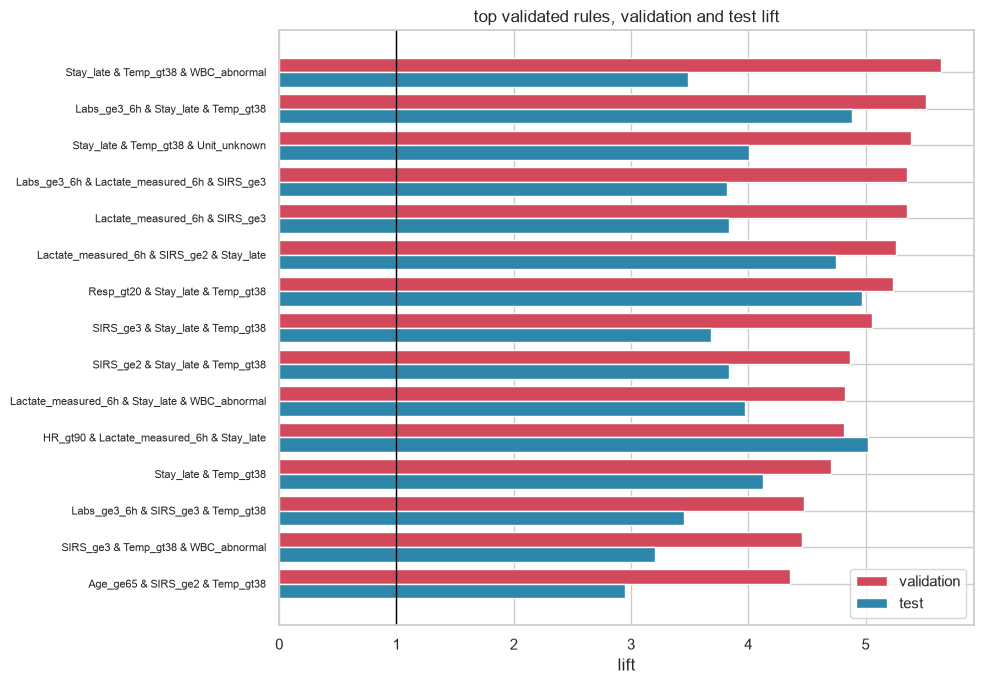

[PASS] validated rules file written before the test evaluation ()
section 8: 0.6s


In [9]:
with timed("section 8"):
    TEST_START = time.time()
    test = df[df["split"] == "test"]
    TI = build_items(test)
    BASE_TEST = TI["Sepsis"].mean()
    log(f"test scored once: {len(TI):,} rows, base rate {BASE_TEST:.4f}")

    validated = pd.concat([validated, rule_stats(TI, validated["antecedent"], "test")], axis=1)
    validated["confirmed"] = (validated["lift_test"] >= 1.5) & (validated["positives_test"] >= 20)
    validated.to_csv(TAB / "ar_rules_validated.csv", index=False)
    item_stats(TI).to_csv(TAB / "ar_item_lift_test.csv", index=False)

    scoring.append(score_row("test", TI))
    sc = pd.DataFrame(scoring)
    sc.to_csv(TAB / "ar_rule_scoring.csv", index=False)
    log(sc.to_string(index=False))

    conf = validated[validated["confirmed"]]
    log(f"confirmed rules: {len(conf)} of {len(validated)} validated")
    log("top confirmed rules:")
    for i, (_, r) in enumerate(conf.head(10).iterrows(), 1):
        log(sentence(i, r, test=True))

    t = validated.head(15).iloc[::-1]
    ypos = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(ypos + 0.2, t["lift_val"], height=0.4, color=SEPTIC, label="validation")
    ax.barh(ypos - 0.2, t["lift_test"], height=0.4, color=CONTROL, label="test")
    ax.axvline(1, color="black", lw=1)
    ax.set_yticks(ypos)
    ax.set_yticklabels(t["antecedent"].str.replace(" AND ", " & "), fontsize=8)
    ax.set_xlabel("lift")
    ax.set_title("top validated rules, validation and test lift")
    ax.legend()
    save_fig("fig10_top_rules.png")

    with guarded("order of writing"):
        jpath = PROC / "ar_rules_validated.json"
        check("validated rules file written before the test evaluation", jpath.exists() and jpath.stat().st_mtime <= TEST_START and WRITE_TIME < TEST_START)

## Output files

Every saved file is listed with its size, and the log is written to the summary file.

In [10]:
with timed("section 9"):
    outs = [PROC / "ar_items_definition.json", PROC / "ar_transactions_train.parquet", PROC / "ar_rules_validated.json",
            TAB / "ar_item_lift_val.csv", TAB / "ar_item_lift_test.csv", TAB / "ar_support_sweep.csv",
            TAB / "ar_rules_train.csv", TAB / "ar_rules_validated.csv", TAB / "ar_rule_scoring.csv"] + SAVED
    absent = 0
    for p in outs:
        if p.exists():
            log(f"{p.relative_to(ROOT)}: {p.stat().st_size / 1e6:.3f} MB")
        else:
            absent += 1
            log(f"{p.relative_to(ROOT)}: MISSING")
    check("all output files present", absent == 0, f"{absent} missing")
    log(f"checks: {COUNTS['pass']} passed, {COUNTS['fail']} failed")
    summ = ROOT / "results" / "step10_summary.txt"
    summ.write_text("\n".join(SUMMARY))
print(summ)

data/processed/ar_items_definition.json: 0.001 MB
data/processed/ar_transactions_train.parquet: 0.225 MB
data/processed/ar_rules_validated.json: 0.016 MB
results/tables/ar_item_lift_val.csv: 0.002 MB
results/tables/ar_item_lift_test.csv: 0.002 MB
results/tables/ar_support_sweep.csv: 0.000 MB
results/tables/ar_rules_train.csv: 0.020 MB
results/tables/ar_rules_validated.csv: 0.037 MB
results/tables/ar_rule_scoring.csv: 0.000 MB
results/figures/fig10_item_lift.png: 0.082 MB
results/figures/fig10_rules_lift_scatter.png: 0.082 MB
results/figures/fig10_top_rules.png: 0.089 MB
[PASS] all output files present (0 missing)
checks: 27 passed, 0 failed
section 9: 0.0s
/Users/harnoorkaur/Downloads/Sepsis_ml/results/step10_summary.txt
